Universidad Torcuato Di Tella

Licenciatura en Tecnología Digital

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**

# **Trabajo Práctico — Ejercicio N°8: Mínimos cuadrados mediante métodos iterativos**

Resolvemos todas las importaciones necesarias para el correcto funcionamiento del código.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Además, corremos los bloques necesarios de ejercicios anteriores para poder realizar este ejercicio:

In [3]:
# Ejercicio 3

# Definimos `X_fantoma`
X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Aplanamos la matriz `X_fantoma` para dar lugar a `x_fantoma`
x_fantoma = X_fantoma.reshape(-1)

In [4]:
# Ejercicio 3
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    r'''
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direccion` -> dirección del rayo (fija una familia de rayos paralelos).
    - `s` -> distancia del rayo al origen (fija un rayo).

    Devuelve:
    - La matriz que representa la mascara del rayo sobre la imagen.
    '''
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

In [5]:
# Ejercicio 3
def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A) # type: ignore
            res.append((dir, rayo))

    return A, res

In [6]:
# Ejercicio 4

# Para definir dimensiones de la matriz (nxn)
n = 8

D2 = [(1,0),(0,1)]
D4 = [(1,0),(0,1),(1,1),(1,-1)]
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]

# Construímos A2, A4, A7
A2 = matriz_proyeccion(n, D2)[0]
A4 = matriz_proyeccion(n, D4)[0]
A7 = matriz_proyeccion(n, D7)[0]

In [7]:
# Ejercicio 5

# Generemos las mediciones
b2 = A2 @ x_fantoma
b4 = A4 @ x_fantoma
b7 = A7 @ x_fantoma

In [8]:
# Ejercicio 6

# Determinamos una semilla aleatoria para garantizar reproducibilidad
SEED = 73
np.random.seed(SEED)

# Creamos el vector z del mismo tamaño que b7, es decir, 119
z = np.random.normal(loc=0.0, scale=1.0, size=119)

# Creamos la lista de desvios (sigma's)
desvios = [0, 0.01, 0.03, 0.06, 0.1]

# Calculamos escala
escala = np.sqrt(np.mean(b7**2))

# Creamos la lista de ruidos (eta's) donde habrá una por cada desvio
ruidos = list()

for ds in desvios:
    ruido = ds * escala * z
    ruidos.append(ruido)

In [9]:
# Ejercicio 6

# Creamos la lista de mediciones con ruido (b_\sigma)
mediciones_ruidosas = list()

for i in range(len(ruidos)):
    med_ruido = b7 + ruidos[i]
    mediciones_ruidosas.append(med_ruido)

In [10]:
# Ejercicio 6

# Creamos una lista con las reconstrucciones por mínimos cuadrados
reconstrucciones = list()

# Creamos una lista con los residuos cuadrados producto de las reconstrucciones
residuos_cuadrados = list()

for med_ruidosa in mediciones_ruidosas:
    # Resolvemos por mínimos cuadrados
    # Obtenemos el \hat{x}_\sigma
    x_ruidoso = np.linalg.lstsq(A7, med_ruidosa)[0]

    # Actualizamos la lista de reconstrucciones
    reconstrucciones.append(x_ruidoso)

    # Calculamos el residuo cuadrado correspondiente
    res_cuad = np.linalg.norm(A7 @ x_ruidoso - med_ruido)**2

    # Actualizamos la list ade residuos cuadrados
    residuos_cuadrados.append(res_cuad)

Resolveremos nuevamente el problema de mínimos cuadrados para $A_7$ y las mediciones ruidosas $b\sigma$, pero esta vez utilizando métodos iterativos. Definimos la función objetivo como:

$$
E(x) = \frac{1}{2}||A_7 x - b_\sigma ||^2
$$

Para este costo, utilizaremos el gradiente $\nabla E(x) = {A^T}_7 (A_7 x − b_\sigma)$ y la Hessiana constante $H = {A^T}_7 A_7$.

1. Interpretar las expresiones provistas e implementar funciones que calculen $E(x)$ y $\nabla E(x)$. Construir también $H$ y verificar numéricamente que es simétrica.

In [11]:
# Para poder operar con A7 como matriz de numpy
A7 = np.array(A7)

# Construcción de E(X)
def E(x, bs):
    b_real = A7@x
    # b_sigma = b_real + ruidos[3]
    return 0.5*(np.linalg.norm(b_real - bs)**2)

# Construcción del gradiente de E(X)
def E_gradient(x, bs):
    b_real = A7@x
    # b_sigma = b_real + ruidos[3]
    return A7.transpose() @ (b_real - bs)

# Función que verifica simetría
def is_simetrical(A:np.ndarray)->bool:
    if np.array_equal(A.transpose(), A): return True
    return False
 
# Construcción de la matriz hessiana y verificación de simetría
matriz_hessiana = A7.transpose() @ A7
print("Es simetrica la matriz? ->", is_simetrical(matriz_hessiana))

Es simetrica la matriz? -> True


De las fórmulas provistas, se intepreta lo siguiente:

- $E(x)\rightarrow$ es la función objetivo a minimizar. Funciona como una métrica que nos indica qué tan cerca está nuestra reconstrucción de la solución real. En particular, es 
- $\nabla E(x)\rightarrow$ es el gradiente de la función objetivo, o bien, el conjunto de todas las primeras derivadas parciales.
- $H_f(x)\rightarrow$ es la matriz hessiana que contiene todas las segundas derivadas parciales de la función objetivo.

Estos lo usaremos para hacer el descenso del gradiente respecto a la distancia entre nuestra solución parcial y la mejor aproximación factible, es decir, aquella para la cual $E(\hat{x}) = \frac{1}{2}||A_7\hat{x} - b_\sigma||² = \frac{1}{2}||b_7 - b_\sigma||² = \frac{1}{2}||r_\sigma||²$.


2. Implementar gradiente descendiente mediante $x_{t+1} = x_t − \alpha \nabla E(x_t)$, comenzando con $x_0 = 0$. Registrar el costo y la norma del gradiente durante las iteraciones.

In [12]:
def gradiente_descendente(x_0, bs, alpha = 0.01, tolerancia = 0.0001, max_iter = 1000, verbose=False): 
  x_t = x_0
  # Definimos un historial para el valor del costo y la norma del gradiente
  cost_log = list()
  grad_norm_log = list()

  iter  = 0

  while iter <= max_iter:
    # Computamos siguiente x a partir de la derivada de la función
    x_tsig = x_t - alpha * E_gradient(x_t,bs)

    # Actualizamos los historiales e imprimimos por pantalla
    cost_log.append(E(x_t,bs))
    grad_norm_log.append(np.linalg.norm(E_gradient(x_t,bs)))
    if verbose: print("Iteración", iter, "-> Mínimo hallado hasta ahora: ", E(x_t,bs), "-- Norma del gradiente: ", np.linalg.norm(E_gradient(x_t,bs)))

    # Chequeamos si ya alcanzamos la convergencia
    if abs(E(x_tsig,bs) - E(x_t,bs)) < tolerancia:
      break

    # Preparamos la siguiente iteración
    x_t = x_tsig
    iter = iter + 1
  return np.array(x_tsig), cost_log, grad_norm_log # type: ignore

A continuación, utilizamos las mediciones $b_\sigma$ obtenidas de aplicar ruido sobre $b_7 = A_7 x_{fantoma}$ para evaluar el desempeño del método del gradiente. Asimismo, fijamos los parámetros del modelo.

In [13]:
ALPHA = 0.05
MAX_ITER = 1000
TOLERANCIA = 0.0001

# Recordemos que mediciones_ruidosas[3] refiere a b_\sigma
x_gd, costos, grad_norms = gradiente_descendente(x_0=np.zeros((64)), bs=mediciones_ruidosas[3], alpha=ALPHA, tolerancia=TOLERANCIA, max_iter=MAX_ITER, verbose=True)

Iteración 0 -> Mínimo hallado hasta ahora:  72.56048297372345 -- Norma del gradiente:  67.03265830123776
Iteración 1 -> Mínimo hallado hasta ahora:  43.36893397433337 -- Norma del gradiente:  53.98028849924631
Iteración 2 -> Mínimo hallado hasta ahora:  28.163404316646673 -- Norma del gradiente:  44.16411501524221
Iteración 3 -> Mínimo hallado hasta ahora:  18.759671967986783 -- Norma del gradiente:  36.26731758404458
Iteración 4 -> Mínimo hallado hasta ahora:  12.633418495603319 -- Norma del gradiente:  29.82081603799146
Iteración 5 -> Mínimo hallado hasta ahora:  8.56106931160392 -- Norma del gradiente:  24.533477659667398
Iteración 6 -> Mínimo hallado hasta ahora:  5.829435559176831 -- Norma del gradiente:  20.18888561298695
Iteración 7 -> Mínimo hallado hasta ahora:  3.9887819666568998 -- Norma del gradiente:  16.616012893270508
Iteración 8 -> Mínimo hallado hasta ahora:  2.745361381934599 -- Norma del gradiente:  13.67659603182734
Iteración 9 -> Mínimo hallado hasta ahora:  1.9040

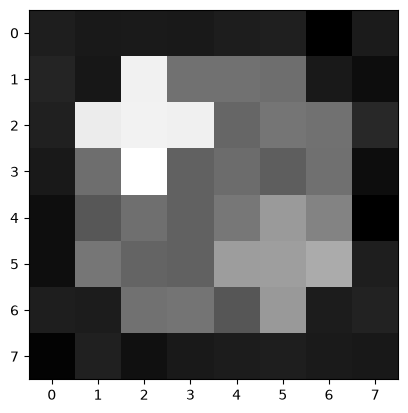

In [14]:
# Graficamos la reconstrucción obtenida mediante este método
X_gd = x_gd.reshape(8,8)
plt.imshow(X_gd, cmap='gray')

3. Calcular el mayor autovalor $\mu _{max}$ de $H$ y probar tasas de aprendizaje dentro y fuera del intervalo $0 < \alpha < 2/ \mu _{max}$. Comparar las curvas del costo y describir cuándo el método converge o se vuelve inestable.

In [15]:
# Buscamos el máximo autovalor
umax = np.max(np.linalg.eig(matriz_hessiana).eigenvalues)
print("umax: ", umax, "-- 2/umax:", 2/umax)

umax:  (36.46340500801554+0j) -- 2/umax: (0.05484951280771369+0j)


Primero, vamos a observar qué sucede para tasas de aprendizaje contenidas en el intervalo. Al mismo tiempo, vamos a ir guardando la evolución de los costos y de la norma del gradiente para cada tasa de aprendizaje evaluada.

In [16]:
curvas_de_costo = list()
curvas_grad_norm = list()

In [17]:
for alpha in [0.01, 0.02, 0.03, 0.04, 0.05, 0.054]:
    x_gd_alpha, costos_alpha, grad_norms_alpha  = gradiente_descendente(x_0=np.zeros((64)), bs=mediciones_ruidosas[3], alpha=alpha, tolerancia=TOLERANCIA, max_iter=MAX_ITER)
    curvas_de_costo.append(costos_alpha)
    curvas_grad_norm.append(grad_norms_alpha)
    print("Para alpha =", alpha, "el mínimo alcanzado es", E(x_gd_alpha, mediciones_ruidosas[3]))

Para alpha = 0.01 el mínimo alcanzado es 0.12972257458893124
Para alpha = 0.02 el mínimo alcanzado es 0.12811372980908523
Para alpha = 0.03 el mínimo alcanzado es 0.12751872626309732
Para alpha = 0.04 el mínimo alcanzado es 0.12720828949463867
Para alpha = 0.05 el mínimo alcanzado es 0.12685453015575943
Para alpha = 0.054 el mínimo alcanzado es 0.12751571574506132


A simple vista, se puede ver que, cuanto más nos acercamos al límite del intervalo, mejores son los resultados obtenidos. Pareciera que las primeras tasas resultan demasiado lentas y convergen muy despacio.

Veamos qué ocurre si nos salimos del intervalo.

In [18]:
# Alpha = 0.055
x_gd_alpha, costos_alpha, grad_norms_alpha = gradiente_descendente(x_0=np.zeros((64)), bs=mediciones_ruidosas[3], alpha=0.055, tolerancia=TOLERANCIA, max_iter=MAX_ITER)
curvas_de_costo.append(costos_alpha)
curvas_grad_norm.append(grad_norms_alpha)
print("Para alpha =", 0.055, "el mínimo alcanzado es", E(x_gd_alpha, mediciones_ruidosas[3]))

# Alpha = 0.06
x_gd_alpha, costos_alpha, grad_norms_alpha = gradiente_descendente(x_0=np.zeros((64)), bs=mediciones_ruidosas[3], alpha=0.06, tolerancia=TOLERANCIA, max_iter=MAX_ITER)
curvas_de_costo.append(costos_alpha)
curvas_grad_norm.append(grad_norms_alpha)
print("Para alpha =", 0.06, "el mínimo alcanzado es", E(x_gd_alpha, mediciones_ruidosas[3]))

Para alpha = 0.055 el mínimo alcanzado es 3298553.400076778
Para alpha = 0.06 el mínimo alcanzado es 2.510087906716196e+151


Incluso si nos pasamos por muy poco del límite, el mínimo obtenido se dispara por los aires, y el método se vuelve inestable.

Gráficamente, esto se puede observar en la forma de las curvas de costo y las curvas de la norma del gradiente. Para las últimas dos tasas evaluadas, $0.055$ y $0.06$, las curvas empiezan a crecer desmesuradamente en lugar de bajar, que es lo que debería suceder si estuvieran convergiendo al mínimo.

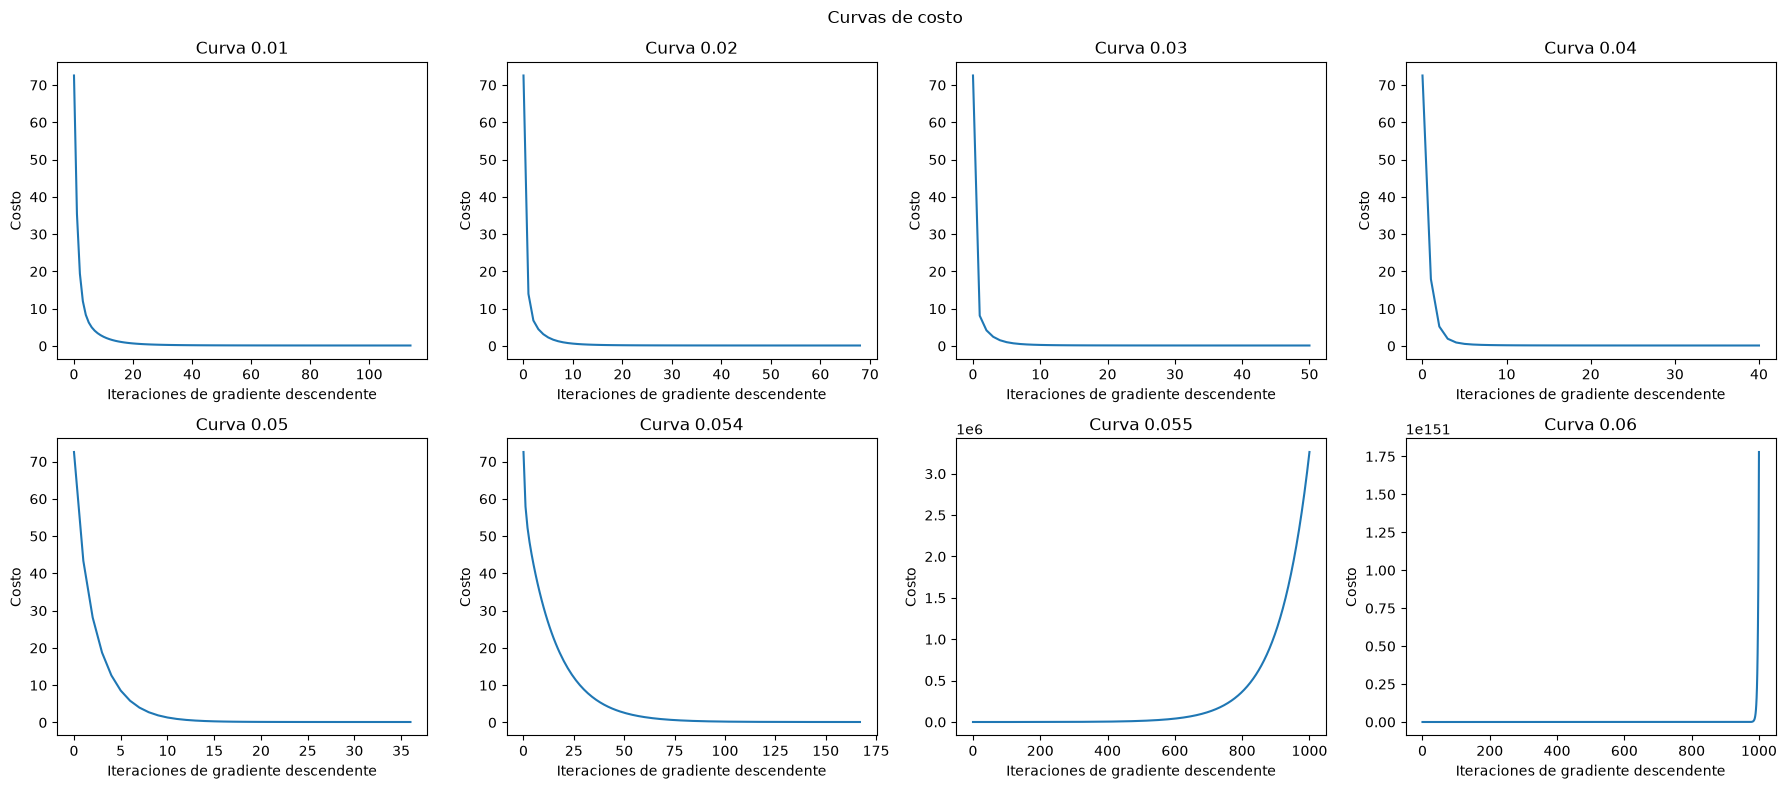

In [19]:
alphas = [0.01, 0.02, 0.03, 0.04, 0.05, 0.054, 0.055, 0.06]

# Generamos una figura grande para graficar los subplots
plt.figure(figsize=(18, 8))

# Delimitamos un título general del plot
plt.suptitle("Curvas de costo")

# Generamos un gráfico para cada curva de costos
# En particular, una por cada valor de alpha
for i in range(len(curvas_de_costo)):
    plt.subplot(2, 4, i+1)
    plt.plot(curvas_de_costo[i])
    plt.title(f'Curva {alphas[i]}')
    plt.ylabel('Costo')
    plt.xlabel('Iteraciones de gradiente descendente')

plt.tight_layout()
plt.show()

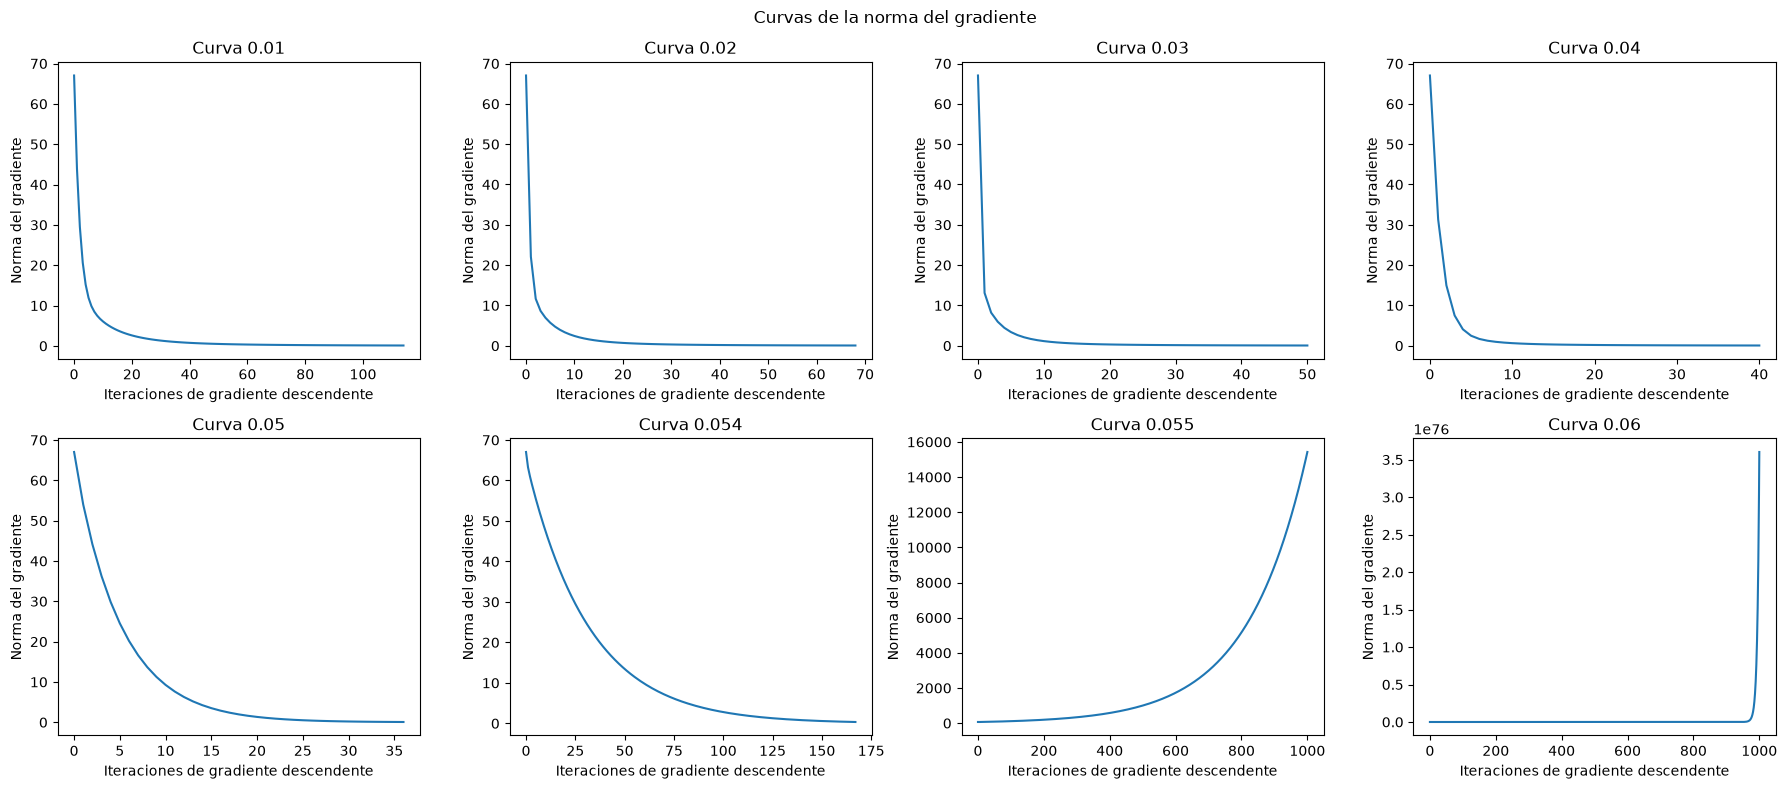

In [20]:
# Generamos una figura grande para graficar los subplots
plt.figure(figsize=(18, 8))

# Delimitamos un título general del plot
plt.suptitle("Curvas de la norma del gradiente")

# Generamos un gráfico para cada curva de la norma del gradiente
# En particular, una por cada valor de alpha
for i in range(len(curvas_grad_norm)):
    plt.subplot(2, 4, i+1)
    plt.plot(curvas_grad_norm[i])
    plt.title(f'Curva {alphas[i]}')
    plt.ylabel('Norma del gradiente')
    plt.xlabel('Iteraciones de gradiente descendente')

plt.tight_layout()
plt.show()

4. Implementar el método de Newton resolviendo $H\text{p}_t = \nabla E(x_t)$ mediante `np.linalg.solve` y actualizando $x_{t+1} = x_t − \text{p}_t$. Verificar que alcanza la solución en una sola iteración y explicar por qué esto ocurre para una función cuadrática con Hessiana constante.

In [21]:
def metodo_newton(x_0, bs, tolerancia = 0.0001, max_iter = 1000, verbose=False):
  x_t   = x_0
  iter  = 0

  while iter <= max_iter:
    if verbose: print("Iteración: ", iter, "- Mínimo alcanzado hasta el momento: ", E(x_t,bs))

    x_tsig = x_t - np.linalg.solve(a=matriz_hessiana, b=E_gradient(x_t,bs))

    # Chequeamos si ya alcanzamos la convergencia
    if abs(E(x_tsig,bs) - E(x_t,bs)) < tolerancia: break
    
    # Preparamos la siguiente iteración
    x_t = x_tsig
    iter = iter + 1

  return np.array(x_tsig) # type: ignore

In [22]:
x_newton = metodo_newton(x_0=np.zeros((64)), bs=mediciones_ruidosas[3], verbose=True)

Iteración:  0 - Mínimo alcanzado hasta el momento:  72.56048297372345
Iteración:  1 - Mínimo alcanzado hasta el momento:  0.12604060608475443


La solución por método de Newton se alcanza en una sola iteración por el siguiente motivo que iremos desarrollando.

En primer lugar, recordemos que estamos lidiando con un método de segundo orden que aproxima mediante el polinomio de Taylor de segundo de la función objetivo $E(x)$. A diferencia del método de mínimos cuadrados, el *learning rate* $\alpha$ se determina en función de la derivada segunda de la función objetivo, en este caso nuestro hessiano $H$.  

Ahora bien, dado que la función objetivo $E(x)$ es cuádratica ello deriva en el hecho de que el hessiano $H(x)$ sea constante para todo $x \in Dom(E)$. De aquí, aún nos falta un paso para comprender el por qué del resultado obtenido.

---

Pensemos cómo se deriva en profundidad el método de Newton aplicado a este caso particular. Definíamos un $\triangle x = x_{t+1} - x_t$ para representar el salto desde la posición previa a la siguiente. Luego, por Taylor de segundo orden sabíamos que:

$$
E(x_{t+1}) \approx E(x_t) + \nabla E(x_t)\triangle x + H(x_t)\frac{\triangle x^2}{2} =  E(x_t) + \nabla E(x_t)\triangle x + H\frac{\triangle x^2}{2} 
$$

Después, buscamos el mínimo derivando $E(x_{t+1})$ respecto a $\triangle x$ e igualando a cero. Esto nos dice qué salto debemos hacer desde donde estamos para llegar hasta al mínimo (se puede pensar como la búsqueda del mínimo relativo a la posición actual). Seguimos desarrollando el calculo:

$$
\frac{d}{d\triangle x}E(x_{t+1}) \approx \nabla E(x_t) + H \frac{2\triangle x}{2} = \nabla E(x_t) + H \triangle x 
$$

Ahora igualamos a cero (ya estamos en el terreno de la aproximación):

$$
\begin{aligned}
0 &= \nabla E(x_t) + H\,\Delta x \\
&\iff 0 = \nabla E(x_t) + H(x_{t+1} - x_t) \\
&\iff -H(x_{t+1} - x_t) = \nabla E(x_t) \\
&\iff -H^{-1}H(x_{t+1} - x_t) = H^{-1}\nabla E(x_t) \\
&\iff -I\,(x_{t+1} - x_t) = H^{-1}\nabla E(x_t) \\
&\iff x_{t+1} - x_t = -H^{-1}\nabla E(x_t) \\
&\iff x_{t+1} = x_t - H^{-1}\nabla E(x_t)
\end{aligned}
$$

Sigamos desarrollando más esta identidad (reemplazamos con las funciones dadas):

$$
\begin{aligned}
& x_{t+1} = x_t - H^{-1}\nabla E(x_t) \\
& \iff  x_{t+1} = x_t - ({A^T}_7 A_7)^{-1} {A^T}_7 (A_7 x_t - b_\sigma) \\
& \iff  x_{t+1} = x_t - ({A_7}^{-1} ({A^T}_7)^{-1}) {A^T}_7 (A_7 x_t - b_\sigma) \\
& \iff  x_{t+1} = x_t - {A_7}^{-1} (({A^T}_7)^{-1} {A^T}_7) (A_7 x_t - b_\sigma) \\
& \iff  x_{t+1} = x_t - {A_7}^{-1} I (A_7 x_t - b_\sigma) \\
& \iff  x_{t+1} = x_t - {A_7}^{-1}(A_7 x_t - b_\sigma) \\
& \iff  x_{t+1} = x_t - ({A_7}^{-1}A_7) x_t + {A_7}^{-1}b_\sigma \\
& \iff  x_{t+1} = x_t - I x_t + {A_7}^{-1}b_\sigma \\
& \iff  x_{t+1} = x_t - x_t + {A_7}^{-1}b_\sigma \\
& \iff  x_{t+1} = {A_7}^{-1}b_\sigma 
\end{aligned}
$$

Verificamos la condición de mínimo:

$$
\begin{aligned}
& \nabla E(x_{t+1}) = \nabla E({A_7}^{-1}b_\sigma)\\
& = {A^T}_7(A_7({A_7}^{-1}b_\sigma) - b_\sigma) \\
& = {A^T}_7((A_7{A_7}^{-1})b_\sigma - b_\sigma) \\
& = {A^T}_7(b_\sigma - b_\sigma) \\
& = {A^T}_7\bar{0} \\
& = \bar{0}
\end{aligned}
$$


---

Luego, tras una iteración resulta que hemos llegado al mínimo (resultado conocido por lo hecho en otros ejercicios) y además verifica la condición de mínimo.

El detalle importante aquí es que gracias a que el hessiano $H$ es constante, el punto $x_t$ del que partamos nos da igual pues la dirección que nos dirige al mínimo es la misma. Por lo tanto, para los casos donde la función objetivo es cuádratica, el polinomio de Taylor de segundo orden resulta ser una expresión equivalente a la función objetivo por lo que la iteración o paso de descenso en el algoritmo se convierte en un mero despeje que nos lleva al óptimo de forma directa.

5. Comparar las reconstrucciones obtenidas mediante gradiente descendiente, Newton y `lstsq`.

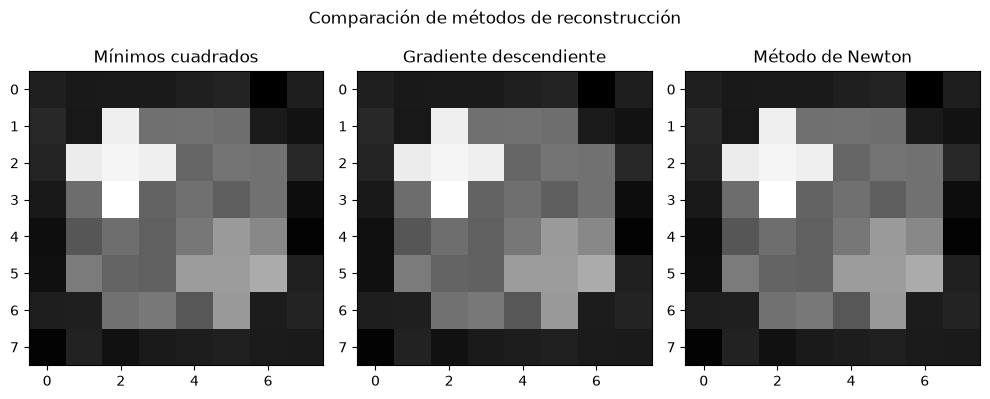

E(X_lstsq) con mínimos cuadrados: 0.12604060608475448
E(X_gd) con descenso del gradiente: 0.12751571574506132
E(X_n) con Newton: 0.12604060608475448


In [ ]:
ALPHA = 0.054
TOLERANCIA = 0.0001
MAX_ITER = 1000

x_lstsq = np.linalg.lstsq(a=A7, b=mediciones_ruidosas[3])[0]
x_gd = gradiente_descendente(x_0=np.zeros((64)), bs=mediciones_ruidosas[3], alpha=ALPHA, tolerancia=TOLERANCIA, max_iter=MAX_ITER)[0]

# Las reconstrucciones halladas por los tres métodos
X_lstsq = x_lstsq.reshape(8,8)
X_gd = x_gd.reshape(8,8)
X_newton = x_newton.reshape(8,8)

# Generamos una figura grande para graficar los subplots
plt.figure(figsize=(10, 4))

# Delimitamos un título general del plot
plt.suptitle("Comparación de métodos de reconstrucción")

# Subplot para el método de mínimos cuadrados
plt.subplot(1, 3, 1)
plt.title('Mínimos cuadrados')
plt.imshow(X_lstsq, cmap='gray')    

# Subplot para el método de gradiente descendente
plt.subplot(1, 3, 2)
plt.title('Gradiente descendiente')
plt.imshow(X_gd, cmap='gray') 

# Subplot para el método de Newton
plt.subplot(1, 3, 3)
plt.title('Método de Newton')
plt.imshow(X_newton, cmap='gray') 

plt.tight_layout()
plt.show()

# Imprimimos la evaluación de los óptimos en la función objetivo según el método empleado
print("E(X_lstsq) con mínimos cuadrados:", E(x_lstsq, mediciones_ruidosas[3]))
print("E(X_gd) con descenso del gradiente:", E(x_gd, mediciones_ruidosas[3]))
print("E(X_n) con método de Newton:", E(x_newton, mediciones_ruidosas[3]))

Si bien la visualización de las reconstrucciones podría sugerir resultados iguales para los tres métodos, al analizar los óptimos evaluados sobre la función objetivo es evidente que **tanto la solución por mínimos cuadrados como la solución por método de Newton llegan a la mejor aproximación**. El método del gradiente también llega a una aproximación muy buena con la tasa de aprendizaje correcta, más no la mejor en términos relativos.